<a href="https://colab.research.google.com/github/aruzhan2345/Image-Classification-using-CNN/blob/main/BDA_2407_Lab6_Aruzhan_Alimkhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6: Image Classification using CNN
**Dataset:** Kaggle Rock-Paper-Scissors Images  
**Student:** Aruzhan Alimkhan | **Group:** BDA-2407



## 1. Dataset and setup
The [Kaggle dataset](https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors) was created by Julien de la Bruère-Terreault for a Raspberry Pi computer-vision game. It contains 2,188 real photographs, taken on a green background with fairly consistent lighting. The original images are 300 × 200 pixels with three RGB (red, green, blue) channels and have three class labels. A label is the recorded category of an image. The dataset is licensed CC BY-SA 4.0.

The archive includes a second copy of the class folders. I use only the top-level copy. The downloaded version has paper=712, rock=726 and scissors=750 (32.54%, 33.18% and 34.28%). Its older README lists 710/726/752; I report the counts measured from the actual files. All image figures in this notebook use this dataset with attribution to its creator; all plots are generated by my code.

In [ ]:
import sys, time, hashlib, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED, SIZE, BATCH = 42, 96, 32
TARGET_ACC, TARGET_F1 = 0.90, 0.90
keras.utils.set_random_seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Python:', sys.version.split()[0], '| TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

Python: 3.13.16 | TensorFlow: 2.21.0 | Keras: 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Business understanding
I want to classify a hand image as **paper, rock or scissors** for a simple camera-based game. The game would use the prediction to identify the player's move and calculate the round result. Predicting **rock when the player shows scissors** is a costly example: against a computer's paper move, it changes a player's win into a loss. Other wrong classes can also produce an unfair score, so every class should be recognised well.

Before training, I set success as test accuracy ≥ 90% and macro F1 ≥ 0.90. These targets are reasonable for a classroom prototype with a controlled background. Validation results will guide model selection; the test set will be used only for the final comparison.

**Metric definitions:** Accuracy is the fraction of correct predictions. For one class, precision is the fraction of predictions for that class that are correct, and recall is the fraction of its actual images correctly found. F1 = 2 × precision × recall / (precision + recall). Macro averaging calculates each class's score first, then gives all classes equal weight. A confusion matrix counts actual classes against predicted classes.

In [ ]:
data_dir = Path('lab6_data')
data_dir.mkdir(exist_ok=True)
archive = data_dir / 'rockpaperscissors.zip'
if not archive.exists():
    urllib.request.urlretrieve(
        'https://www.kaggle.com/api/v1/datasets/download/drgfreeman/rockpaperscissors', archive)
if not all((data_dir / c).exists() for c in ['paper', 'rock', 'scissors']):
    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            if len(Path(name).parts) == 2 and Path(name).parts[0] in ['paper', 'rock', 'scissors']:
                z.extract(name, data_dir)
classes = ['paper', 'rock', 'scissors']
print('Using one copy of the Kaggle images:', data_dir)

Using one copy of the Kaggle images: lab6_data


## 3. EDA and cleaning


In [ ]:
records, corrupt = [], []
for class_id, name in enumerate(classes):
    for path in sorted((data_dir / name).glob('*.png')):
        try:
            with Image.open(path) as im:
                im.load()
                digest = hashlib.sha256(str((im.size, im.mode)).encode() + im.tobytes()).hexdigest()
                records.append([str(path), class_id, im.width, im.height, im.mode, digest])
        except (OSError, ValueError) as e:
            corrupt.append((str(path), str(e)))
images = pd.DataFrame(records, columns=['path', 'label', 'width', 'height', 'mode', 'hash'])
raw_count = len(images)
conflicting = images.groupby('hash')['label'].nunique()
bad_hashes = conflicting[conflicting > 1].index
duplicate_count = images.duplicated('hash').sum()
images = images[~images['hash'].isin(bad_hashes)].drop_duplicates('hash').reset_index(drop=True)
print(f'Decoded: {raw_count}; corrupted: {len(corrupt)}; exact extra copies: {duplicate_count}; conflicting hashes: {len(bad_hashes)}')
print('Observed original formats:')
display(images.groupby(['width', 'height', 'mode']).size().rename('images').to_frame())
balance = images['label'].value_counts().reindex(range(3)).rename_axis('class_id').to_frame('images')
balance.index = classes
balance['percent'] = (100 * balance['images'] / len(images)).round(2)
display(balance)
print('Clean images:', len(images))
assert len(images) > 1000

Decoded: 2188; corrupted: 0; exact extra copies: 0; conflicting hashes: 0
Observed original formats:


,,,images
width,height,mode,
300,200,RGB,2188


,images,percent
paper,712,32.54
rock,726,33.18
scissors,750,34.28


Clean images: 2188


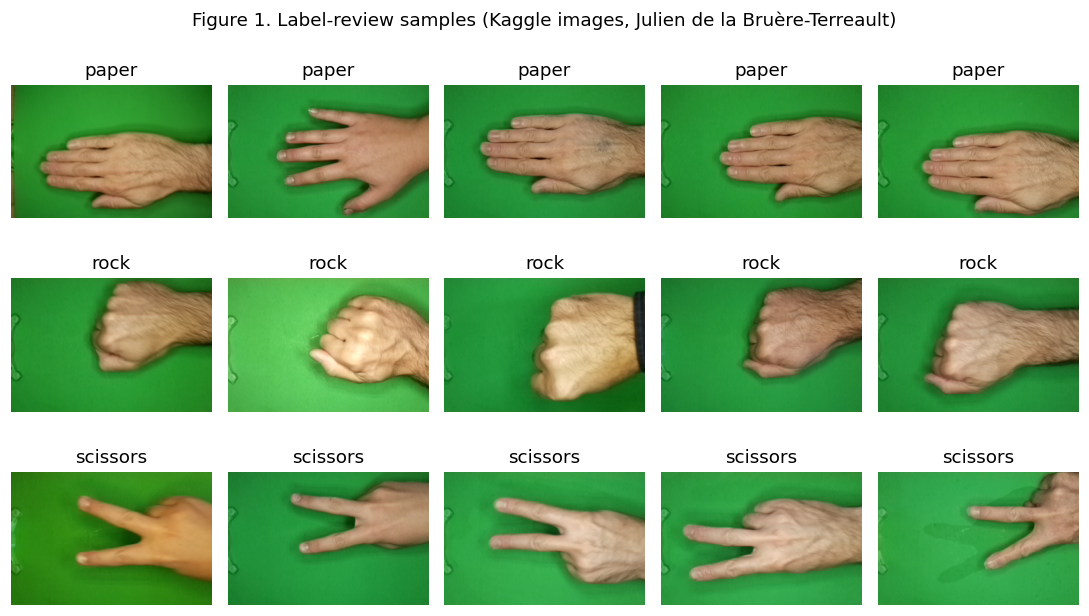

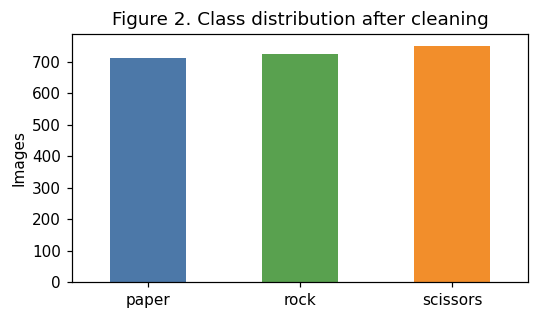

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for label, row in enumerate(axes):
    sample = images[images.label == label].sample(5, random_state=SEED)
    for ax, path in zip(row, sample.path):
        with Image.open(path) as im:
            ax.imshow(im)
        ax.set_title(classes[label]); ax.axis('off')
fig.suptitle('Figure 1. Label-review samples (Kaggle images, Julien de la Bruère-Terreault)')
plt.tight_layout(); plt.show()
balance['images'].plot.bar(rot=0, figsize=(5, 3), color=['#4C78A8', '#59A14F', '#F28E2B'])
plt.title('Figure 2. Class distribution after cleaning'); plt.ylabel('Images')
plt.tight_layout(); plt.show()

**Label and balance review:** I found no obvious incorrect labels among the 15 displayed examples. This is a sample check, not a complete label verification. All 2,188 files decoded as 300 × 200 RGB images; no corruption, exact duplicates or conflicting labels were found. The classes are nearly balanced, so I keep their natural proportions.

## 4. Preprocessing


,Train,Validation,Test
paper,498,107,107
rock,508,109,109
scissors,525,112,113


{'Train': 1531, 'Validation': 328, 'Test': 329}
Input shape: (1531, 96, 96, 3) | training pixel range: (np.float32(0.0), np.float32(1.0))


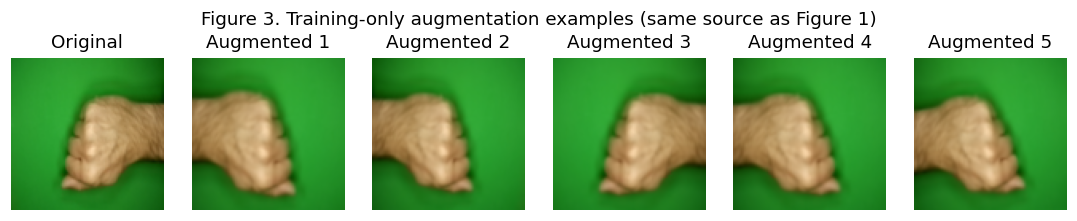

In [ ]:
train_idx, hold_idx = train_test_split(images.index, test_size=0.30, stratify=images.label, random_state=SEED)
val_idx, test_idx = train_test_split(hold_idx, test_size=0.50, stratify=images.loc[hold_idx, 'label'], random_state=SEED)
split_ids = {'Train': train_idx, 'Validation': val_idx, 'Test': test_idx}
display(pd.DataFrame({name: images.loc[idx, 'label'].value_counts().reindex(range(3))
                      for name, idx in split_ids.items()}).set_axis(classes))
print({name: len(idx) for name, idx in split_ids.items()})
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))

def load_split(idx):
    x = np.stack([np.asarray(Image.open(p).convert('RGB').resize((SIZE, SIZE), Image.Resampling.BILINEAR))
                  for p in images.loc[idx, 'path']]).astype('float32') / 255.0
    return x, images.loc[idx, 'label'].to_numpy(dtype='int32')

x_train, y_train = load_split(train_idx)
x_val, y_val = load_split(val_idx)
x_test, y_test = load_split(test_idx)

def dataset(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return ds.batch(BATCH).with_options(options).prefetch(1)

val_ds = dataset(x_val, y_val)
print('Input shape:', x_train.shape, '| training pixel range:', (x_train.min(), x_train.max()))

def augmentation():
    return keras.Sequential([layers.RandomFlip('horizontal', seed=SEED),
                             layers.RandomRotation(0.04, seed=SEED + 1),
                             layers.RandomZoom(0.10, seed=SEED + 2)], name='augmentation')
у
augmented = augmentation()(tf.repeat(x_train[:1], repeats=5, axis=0), training=True).numpy()
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[0] if i == 0 else np.clip(augmented[i-1], 0, 1))
    ax.set_title('Original' if i == 0 else f'Augmented {i}'); ax.axis('off')
fig.suptitle('Figure 3. Training-only augmentation examples (same source as Figure 1)')
plt.tight_layout(); plt.show()

## 5. Training and model definitions


In [ ]:
models, histories, times, validation_rows = {}, {}, {}, []

def compile_model(model, lr=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7)]

def metric_scores(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=range(3), average='macro', zero_division=0)
    return accuracy_score(y, pred), p, r, f

def fit_model(name, model, epochs=25, lr=1e-3):
    compile_model(model, lr)
    start = time.perf_counter()
    history = model.fit(dataset(x_train, y_train, True), validation_data=val_ds,
                        epochs=epochs, callbacks=callbacks(), verbose=0).history
    elapsed = time.perf_counter() - start
    pred = model.predict(val_ds, verbose=0).argmax(axis=1)
    acc, _, _, f1 = metric_scores(y_val, pred)
    models[name], histories[name], times[name] = model, history, elapsed
    validation_rows.append({'Model': name, 'Val accuracy': acc, 'Val macro F1': f1,
                            'Epochs': len(history['loss']), 'Training seconds': elapsed})
    print(f'{name}: {len(history["loss"])} epochs, val accuracy={acc:.4f}, val macro F1={f1:.4f}, time={elapsed:.1f}s', flush=True)
    return history

keras.utils.set_random_seed(SEED)
dense = keras.Sequential([layers.Input((SIZE, SIZE, 3)), layers.Flatten(),
                          layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
                          layers.Dropout(0.3), layers.Dense(64, activation='relu'),
                          layers.Dense(3, activation='softmax')], name='dense_baseline')
fit_model('Dense', dense);

Dense: 25 epochs, val accuracy=0.6829, val macro F1=0.6716, time=14.1s


### CNN and manual first-layer calculation
The CNN uses 16, 32 and 64 filters, doubling after each pooling layer. The first convolution has input 96 × 96 × 3, 16 filters of 3 × 3, stride (step size) 1 and `same` padding (added border pixels that preserve spatial size). The spatial calculation is floor((96 + 2 × 1 − 3) / 1) + 1 = 96 for both height and width. The spatial calculation is floor((96 + 2 × 1 − 3) / 1) + 1 = 96 for both height and width. Thus its output is 96 × 96 × 16, and its parameter count is (3 × 3 × 3 + 1 bias) × 16 = 448. The summary below verifies both values.

In [ ]:
def build_cnn(augment=False, dropout=0.3):
    model = keras.Sequential([layers.Input((SIZE, SIZE, 3))], name='scratch_cnn')
    if augment:
        model.add(augmentation())
    for filters in [16, 32, 64]:
        model.add(layers.Conv2D(filters, 3, padding='same', activation='relu', kernel_initializer='he_normal'))
        model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal'))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(3, activation='softmax'))
    return model

keras.utils.set_random_seed(SEED)
cnn_plain = build_cnn()
cnn_plain.summary()
first_conv = next(layer for layer in cnn_plain.layers if isinstance(layer, layers.Conv2D))
assert tuple(first_conv.output.shape[1:]) == (96, 96, 16)
assert first_conv.count_params() == 448
fit_model('CNN: no augmentation, dropout 0.3', cnn_plain);

Model: "scratch_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       589,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 613,667 (2.34 MB)

 Trainable params: 613,667 (2.34 MB)

 Non-trainable params: 0 (0.00 B)

CNN: no augmentation, dropout 0.3: 17 epochs, val accuracy=0.9787, val macro F1=0.9785, time=22.4s


## 6. Tuning with validation data
I change one thing at a time: first add augmentation while keeping dropout at 0.3, then increase dropout to 0.5 while keeping augmentation. This tests augmentation and one additional setting. The CNN with the highest validation macro F1 is selected, with validation accuracy used to break a tie. The test set stays untouched.

In [ ]:
for name, dropout in [('CNN: augmentation, dropout 0.3', 0.3), ('CNN: augmentation, dropout 0.5', 0.5)]:
    keras.utils.set_random_seed(SEED)
    fit_model(name, build_cnn(augment=True, dropout=dropout))
validation = pd.DataFrame(validation_rows).set_index('Model')
display(validation.round(4))
cnn_candidates = validation[validation.index.str.startswith('CNN:')]
cnn_name = cnn_candidates.sort_values(['Val macro F1', 'Val accuracy'], ascending=False).index[0]
print('Selected CNN using validation only:', cnn_name)

CNN: augmentation, dropout 0.3: 14 epochs, val accuracy=0.9878, val macro F1=0.9877, time=12.5s
CNN: augmentation, dropout 0.5: 25 epochs, val accuracy=0.9909, val macro F1=0.9907, time=15.9s


,Val accuracy,Val macro F1,Epochs,Training seconds
Model,,,,
Dense,0.6829,0.6716,25,14.0695
"CNN: no augmentation, dropout 0.3",0.9787,0.9785,17,22.4304
"CNN: augmentation, dropout 0.3",0.9878,0.9877,14,12.4671
"CNN: augmentation, dropout 0.5",0.9909,0.9907,25,15.9371


Selected CNN using validation only: CNN: augmentation, dropout 0.5


### Transfer learning: frozen model and fine-tuning
Transfer learning reuses features from a model trained on other data. I use MobileNetV2, an efficient CNN pretrained on ImageNet, a large labelled image collection. First I freeze its weights and train a new classification head for up to 10 epochs. Then I unfreeze the last 30 layers, except batch normalization, and fine-tune for up to 10 epochs at a smaller learning rate (0.00001 instead of 0.001). Fine-tuning means updating selected pretrained weights for this task.

Global average pooling averages each feature map into one value. Batch normalization standardizes activations using batch statistics during training and stored statistics at prediction time; it stays in prediction mode here to protect the pretrained statistics. Inputs are scaled to [0, 1], then adapted inside this model to MobileNetV2's expected [-1, 1]. The smaller width alpha=0.35 reduces computing cost. The validation table reports each transfer stage separately; the final comparison adds both training times.

In [ ]:
keras.utils.set_random_seed(SEED)
base = keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), alpha=0.35, include_top=False, weights='imagenet')
base.trainable = False
inputs = keras.Input((SIZE, SIZE, 3))
x = augmentation()(inputs)
x = layers.Rescaling(2.0, offset=-1.0)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation='softmax')(x)
transfer = keras.Model(inputs, outputs, name='mobilenetv2_transfer')
head_history = fit_model('MobileNetV2 frozen', transfer, epochs=10)

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers[-30:]:
    layer.trainable = not isinstance(layer, layers.BatchNormalization)
fine_history = fit_model('MobileNetV2 fine-tuned', transfer, epochs=10, lr=1e-5)
times['MobileNetV2 fine-tuned'] += times['MobileNetV2 frozen']
transfer_history = {key: head_history[key] + fine_history[key] for key in ['loss', 'val_loss', 'accuracy', 'val_accuracy']}
validation = pd.DataFrame(validation_rows).set_index('Model')
display(validation.round(4))

2019640/2019640 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
MobileNetV2 frozen: 10 epochs, val accuracy=0.9939, val macro F1=0.9939, time=15.7s
MobileNetV2 fine-tuned: 10 epochs, val accuracy=0.9939, val macro F1=0.9939, time=17.4s


,Val accuracy,Val macro F1,Epochs,Training seconds
Model,,,,
Dense,0.6829,0.6716,25,14.0695
"CNN: no augmentation, dropout 0.3",0.9787,0.9785,17,22.4304
"CNN: augmentation, dropout 0.3",0.9878,0.9877,14,12.4671
"CNN: augmentation, dropout 0.5",0.9909,0.9907,25,15.9371
MobileNetV2 frozen,0.9939,0.9939,10,15.7098
MobileNetV2 fine-tuned,0.9939,0.9939,10,17.4145


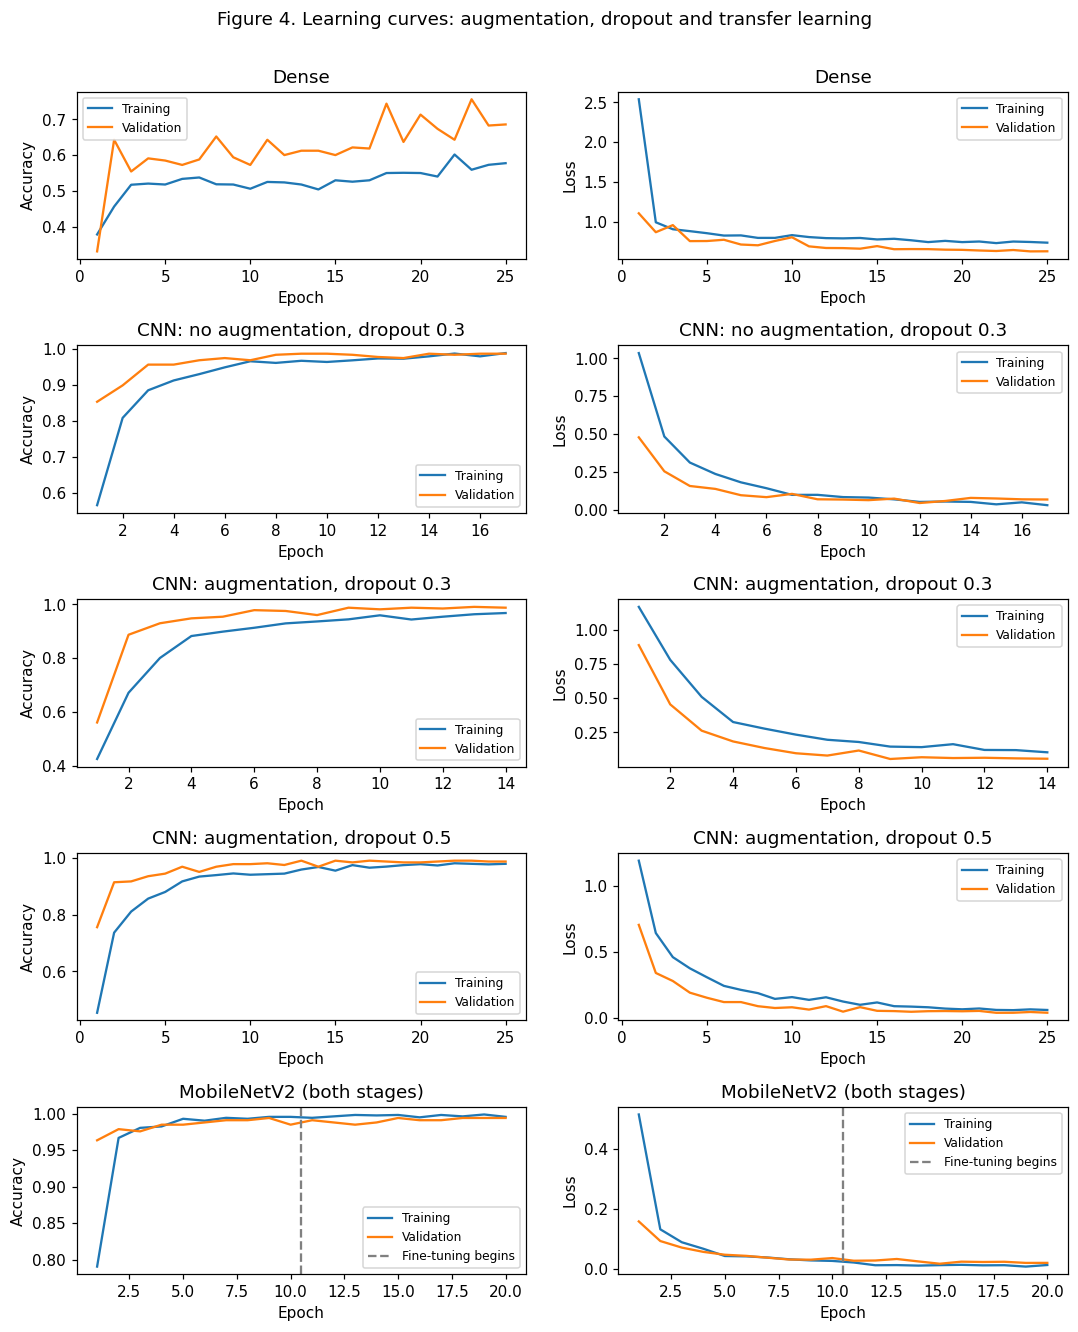

Augmentation change in validation macro F1: +0.0092
Dropout 0.3 → 0.5 change in validation macro F1: +0.0030


In [ ]:
curve_names = ['Dense'] + list(cnn_candidates.index) + ['MobileNetV2 (both stages)']
fig, axes = plt.subplots(len(curve_names), 2, figsize=(10, 12))
for row, name in enumerate(curve_names):
    h = transfer_history if name.startswith('MobileNetV2') else histories[name]
    for col, metric in enumerate(['accuracy', 'loss']):
        ax = axes[row, col]
        epochs = np.arange(1, len(h[metric]) + 1)
        ax.plot(epochs, h[metric], label='Training')
        ax.plot(epochs, h['val_' + metric], label='Validation')
        if name.startswith('MobileNetV2'):
            ax.axvline(len(head_history['loss']) + 0.5, color='gray', ls='--', label='Fine-tuning begins')
        ax.set(title=name, xlabel='Epoch', ylabel=metric.capitalize())
        ax.legend(fontsize=8)
fig.suptitle('Figure 4. Learning curves: augmentation, dropout and transfer learning', y=1.005)
plt.tight_layout(); plt.show()

aug_effect = validation.loc['CNN: augmentation, dropout 0.3', 'Val macro F1'] - validation.loc['CNN: no augmentation, dropout 0.3', 'Val macro F1']
drop_effect = validation.loc['CNN: augmentation, dropout 0.5', 'Val macro F1'] - validation.loc['CNN: augmentation, dropout 0.3', 'Val macro F1']
print(f'Augmentation change in validation macro F1: {aug_effect:+.4f}')
print(f'Dropout 0.3 → 0.5 change in validation macro F1: {drop_effect:+.4f}')



## 7. Final evaluation


Preferred model selected before test predictions: MobileNetV2


,Accuracy,Precision,Recall,F1,Parameters,Training seconds,Meets both targets
Model,,,,,,,
Dense,0.6778,0.6896,0.6754,0.6726,3547523,14.0695,False
CNN,0.9909,0.9911,0.9907,0.9908,613667,15.9371,True
MobileNetV2,0.9970,0.9971,0.9969,0.9970,414051,33.1243,True


At least one model meets both predeclared criteria: True


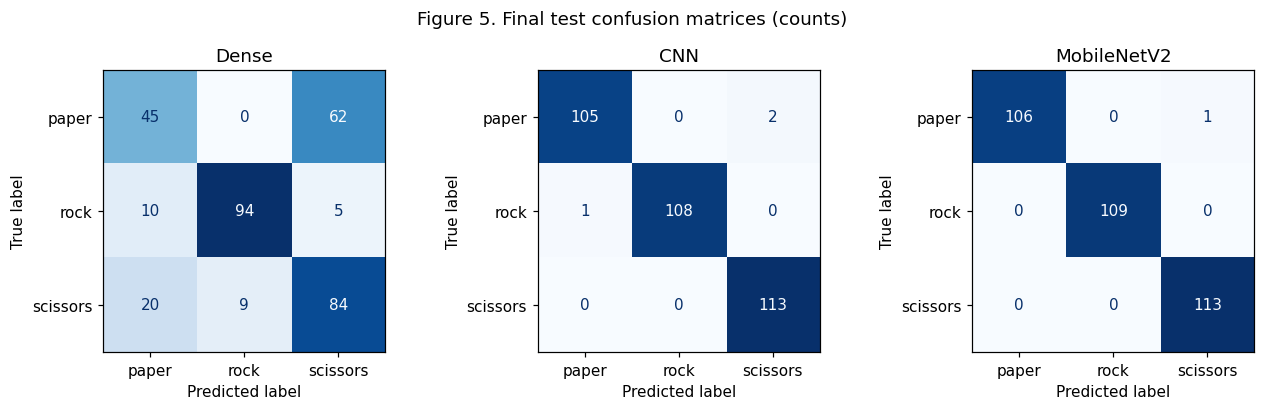

In [ ]:
final_models = {'Dense': models['Dense'], 'CNN': models[cnn_name], 'MobileNetV2': transfer}
final_names = {'Dense': 'Dense', 'CNN': cnn_name, 'MobileNetV2': 'MobileNetV2 fine-tuned'}
validation_winner = max(final_models, key=lambda name: (validation.loc[final_names[name], 'Val macro F1'],
                                                       validation.loc[final_names[name], 'Val accuracy']))
print('Preferred model selected before test predictions:', validation_winner)
test_ds = dataset(x_test, y_test)
test_predictions, result_rows = {}, []
for name, model in final_models.items():
    pred = model.predict(test_ds, verbose=0).argmax(axis=1)
    test_predictions[name] = pred
    acc, precision, recall, f1 = metric_scores(y_test, pred)
    result_rows.append({'Model': name, 'Accuracy': acc, 'Precision': precision, 'Recall': recall, 'F1': f1,
                        'Parameters': model.count_params(), 'Training seconds': times[final_names[name]],
                        'Meets both targets': bool(acc >= TARGET_ACC and f1 >= TARGET_F1)})
comparison = pd.DataFrame(result_rows).set_index('Model')
display(comparison.round(4))
print('At least one model meets both predeclared criteria:', bool(comparison['Meets both targets'].any()))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, (name, pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=range(3)), display_labels=classes).plot(
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.suptitle('Figure 5. Final test confusion matrices (counts)')
plt.tight_layout(); plt.show()

### Five misclassified test images
I show mistakes from the finalized model with the most test errors, so the examples remain useful even if the best model makes fewer than five mistakes. They are five different test images, with actual and predicted labels. Possible causes below are visual interpretations, not proven explanations.

Error examples from: Dense | available errors: 106


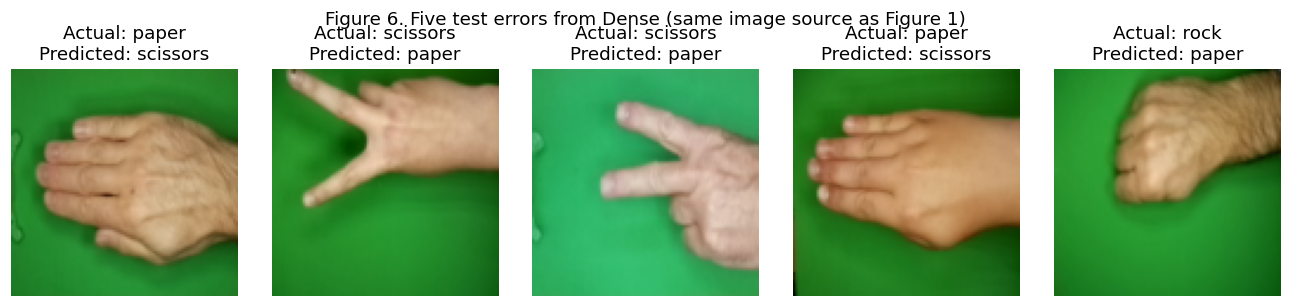

In [ ]:
error_model = max(test_predictions, key=lambda name: np.count_nonzero(test_predictions[name] != y_test))
wrong = np.flatnonzero(test_predictions[error_model] != y_test)[:5]
print('Error examples from:', error_model, '| available errors:', np.count_nonzero(test_predictions[error_model] != y_test))
fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))
for ax, idx in zip(axes, wrong):
    ax.imshow(x_test[idx]); ax.axis('off')
    ax.set_title(f'Actual: {classes[y_test[idx]]}\nPredicted: {classes[test_predictions[error_model][idx]]}')
for ax in axes[len(wrong):]:
    ax.axis('off')
fig.suptitle(f'Figure 6. Five test errors from {error_model} (same image source as Figure 1)')
plt.tight_layout(); plt.show()



### Comparing the models
The selected CNN scored 99.09% accuracy and 0.9909 macro F1, compared with 67.78% and 0.6778 for the dense baseline. It also uses fewer parameters: 613,667 versus 3,547,523. Convolution keeps nearby pixels together and shares filters across positions, helping it recognise finger shapes with fewer weights. Pooling also helps tolerate small position changes; it does not guarantee full shift invariance.

MobileNetV2 was selected using validation results before test evaluation. It had the best test result too: 99.70% accuracy and 0.9970 macro F1, with 414,051 parameters. Both it and the CNN meet the two success criteria. MobileNetV2 made one error and the CNN made two out of 329 test images, so this small difference does not establish that it will always be better. Its reused image features and short measured training time make it my preferred model for this prototype.

## 8. Conclusion
MobileNetV2 was the best model in this run, reaching 99.70% test accuracy and 0.9970 macro F1. It met both targets of 90% accuracy and 0.90 macro F1; the CNN also met them. The CNN clearly improved on the dense baseline, and augmentation plus higher dropout gave a small validation improvement.

The main limitations are the controlled green background and the image-level split, which may place similar photos from the same person or capture session in different sets. These scores therefore describe this dataset, not general webcam performance. Next, I would collect photos with more people, backgrounds and lighting conditions, then test on people and capture sessions kept completely separate from training.

## 9. References
1. Julien de la Bruère-Terreault. [Rock-Paper-Scissors Images, Kaggle](https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors). Dataset and photographs; CC BY-SA 4.0. The archive README is the source for original capture conditions and image format.
2. Dataset creator. [rps-cv project](https://github.com/DrGFreeman/rps-cv). Original Raspberry Pi application and collection context.
3. Scikit-learn. [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).
4. Keras. [Layers API](https://keras.io/api/layers/) and [training with built-in methods](https://keras.io/guides/training_with_built_in_methods/).
5. Keras. [Image augmentation layers](https://keras.io/api/layers/preprocessing_layers/image_augmentation/).
6. Keras. [Adam optimizer](https://keras.io/api/optimizers/adam/).
7. Keras. [EarlyStopping](https://keras.io/api/callbacks/early_stopping/) and [ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/).
8. Keras. [Transfer learning and fine-tuning guide](https://keras.io/guides/transfer_learning/).
9. Keras. [MobileNetV2](https://keras.io/api/applications/mobilenet/mobilenet_models/#mobilenetv2-function); Sandler et al. (2018), [MobileNetV2: Inverted Residuals and Linear Bottlenecks](https://arxiv.org/abs/1801.04381).

